# 23CSE301 Machine Learning — Capstone Project
## Notebook 1 of 3 · Regression Track (Review 1 scope, final version)
**Project**: Food Delivery Duration Prediction & Service Delay Classification Pipeline
**Dataset**: Food Delivery Logistics Dataset (`train.csv`, 45,593 orders × 20 columns)
**Task**: Predict the delivery duration `Time_taken` in minutes.

| Rubric item (Review 1) | Where it is covered |
|---|---|
| **A1** Dataset loading & audit | Section 1 |
| **A2 / A3** EDA visualisations + written insights | Section 2 |
| **B1 / B2 / B3** Cleaning, encoding/scaling/splitting, feature engineering | Section 3 |
| **C1** All 10 regression algorithms | Section 4 |
| **C2** Summary table ranked by R², 5-fold CV of top 2 | Section 5 |
| **C3** Hyperparameter tuning (GridSearchCV on 3 models) | Section 6 |
| **C4** Predicted-vs-actual, residual and feature-importance plots | Section 7 |

Following Guideline 7.1 and Section 8 (one notebook per track), this notebook holds the full regression track. `classification.ipynb` and `clustering.ipynb` hold the Review 2 tracks.

---
### 0. Environment setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, warnings

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
print('Libraries loaded.')

Libraries loaded.


---
### 1. Dataset loading & audit  [Rubric A1]
Missing values in this dataset are hidden as text such as `'NaN '` and `'conditions NaN'`, so `isnull()` alone reports zero. The audit therefore also counts these text tokens.

In [2]:
# ---------------------------------------------------------------------------
# Shared data-preparation functions (identical across regression, classification
# and clustering notebooks so every track uses exactly the same cleaned data).
# ---------------------------------------------------------------------------
import os

RANDOM_STATE = 42
DATA_CANDIDATES = ['train.csv', 'data/train.csv', '../data/train.csv']


def load_raw_data():
    """Load train.csv from the notebook folder or the repo's data/ folder."""
    for path in DATA_CANDIDATES:
        if os.path.exists(path):
            return pd.read_csv(path)
    raise FileNotFoundError(f'train.csv not found in any of {DATA_CANDIDATES}')


def haversine_dist(lon1, lat1, lon2, lat2):
    """Vectorised great-circle distance in km between two sets of coordinates."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def clean_and_engineer(df_raw, verbose=True):
    """Review 1 cleaning + feature-engineering pipeline, wrapped as one function."""
    df = df_raw.copy()

    # 1. Targets: numeric delivery time (regression) and SLA-breach flag (classification)
    df['Time_taken'] = df['Time_taken(min)'].astype(str).str.extract(r'(\d+)')[0].astype(float)
    df['Is_Delayed'] = (df['Time_taken'] > 25.0).astype(int)

    # 2. Strip whitespace and turn hidden 'NaN' string tokens into real missing values
    text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip().replace({'NaN': np.nan, 'nan': np.nan, '': np.nan})
    df['Weatherconditions'] = (df['Weatherconditions'].str.replace('conditions ', '', regex=False)
                               .replace({'NaN': np.nan, 'nan': np.nan}))

    # 3. Numeric casting and rating outliers (ratings > 5 are data-entry errors)
    for col in ['Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    n_rating_outliers = int((df['Delivery_person_Ratings'] > 5.0).sum())
    df.loc[df['Delivery_person_Ratings'] > 5.0, 'Delivery_person_Ratings'] = 5.0

    # 4. Haversine distance; invalid (near-zero) coordinates replaced by the median distance
    lat1, lon1 = df['Restaurant_latitude'].abs(), df['Restaurant_longitude'].abs()
    lat2, lon2 = df['Delivery_location_latitude'].abs(), df['Delivery_location_longitude'].abs()
    df['distance_km'] = haversine_dist(lon1, lat1, lon2, lat2)
    valid = (lat1 > 1.0) & (lon1 > 1.0) & (lat2 > 1.0) & (lon2 > 1.0)
    df.loc[~valid, 'distance_km'] = df.loc[valid, 'distance_km'].median()

    # 5. Kitchen preparation time (order placed -> order picked up), overnight wrap fixed
    t_order = pd.to_datetime(df['Order_Date'] + ' ' + df['Time_Orderd'], format='%d-%m-%Y %H:%M:%S', errors='coerce')
    t_picked = pd.to_datetime(df['Order_Date'] + ' ' + df['Time_Order_picked'], format='%d-%m-%Y %H:%M:%S', errors='coerce')
    prep = (t_picked - t_order).dt.total_seconds() / 60.0
    prep = prep.where(prep >= 0, prep + 1440.0)
    df['prep_time_min'] = prep.fillna(prep.median())

    # 6. Temporal features
    df['order_hour'] = t_order.dt.hour.fillna(17)
    df['is_rush_hour'] = df['order_hour'].isin([12, 13, 14, 19, 20, 21]).astype(int)
    order_date = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y', errors='coerce')
    df['day_of_week'] = order_date.dt.dayofweek.fillna(2)
    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)
    df['Festival_binary'] = (df['Festival'] == 'Yes').astype(int)

    # 7. Ordinal traffic level (used by the clustering track)
    df['traffic_level'] = df['Road_traffic_density'].map({'Low': 0, 'Medium': 1, 'High': 2, 'Jam': 3})

    if verbose:
        print(f'Rows: {len(df):,} | rating outliers capped: {n_rating_outliers} | '
              f'coordinate anomalies fixed: {int((~valid).sum())} | duplicate IDs: {int(df["ID"].duplicated().sum())}')
    return df


NUMERICAL_COLS = ['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'prep_time_min',
                  'order_hour', 'Vehicle_condition', 'multiple_deliveries', 'Festival_binary',
                  'is_rush_hour', 'is_weekend']
CATEGORICAL_COLS = ['Weatherconditions', 'Road_traffic_density', 'City', 'Type_of_vehicle']


def build_preprocessor():
    """Median-impute + scale numerics; mode-impute + one-hot categoricals. Fit on TRAIN only."""
    num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
    cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                         ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))])
    return ColumnTransformer([('num', num_pipe, NUMERICAL_COLS), ('cat', cat_pipe, CATEGORICAL_COLS)])


def get_feature_names(preprocessor):
    cat_names = preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(CATEGORICAL_COLS)
    return NUMERICAL_COLS + list(cat_names)

df_raw = load_raw_data()
print(f'Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
print(f'Fully duplicated rows: {df_raw.duplicated().sum()} | duplicated order IDs: {df_raw["ID"].duplicated().sum()}')

audit = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'isnull()': df_raw.isnull().sum(),
    'hidden NaN tokens': df_raw.apply(lambda c: c.astype(str).str.strip().str.contains(r'NaN$').sum()),
    'unique values': df_raw.nunique(),
    'example': df_raw.iloc[0],
})
display(audit)

Shape: 45,593 rows x 20 columns
Fully duplicated rows: 0 | duplicated order IDs: 0


,dtype,isnull(),hidden NaN tokens,unique values,example
ID,str,0,0,45593,0x4607
Delivery_person_ID,str,0,0,1320,INDORES13DEL02
Delivery_person_Age,str,0,1854,23,37
Delivery_person_Ratings,str,0,1908,29,4.9
Restaurant_latitude,float64,0,0,657,22.7450
Restaurant_longitude,float64,0,0,518,75.8925
Delivery_location_latitude,float64,0,0,4373,22.7650
Delivery_location_longitude,float64,0,0,4373,75.9125
Order_Date,str,0,0,44,19-03-2022
Time_Orderd,str,0,1731,177,11:30:00


#### Observation 1: Data audit
- **45,593 orders × 20 columns, no duplicated rows or order IDs**, so no deduplication is needed.
- `isnull()` reports **0 missing values everywhere, which is misleading**. The text-token count reveals the real gaps: `Delivery_person_Ratings` (1,908), `Delivery_person_Age` (1,854), `Time_Orderd` (1,731), `City` (1,200), `multiple_deliveries` (993), `Weatherconditions` (616), `Road_traffic_density` (601) and `Festival` (228).
- Age, ratings and multiple deliveries are stored as **text** because of those tokens, and the target is text in the form `"(min) 24"`. All need parsing before modelling.
- The raw lat/long columns carry no meaning to a model on their own. They are turned into a distance in Section 3.

---
### 2. Exploratory data analysis  [Rubric A2 / A3]
We clean a copy of the data first (Section 3 explains every step) so that the plots show real numbers and not text.

In [3]:
df = clean_and_engineer(df_raw)
df['Weather'] = df['Weatherconditions']
df['Traffic'] = df['Road_traffic_density']

Rows: 45,593 | rating outliers capped: 53 | coordinate anomalies fixed: 3640 | duplicate IDs: 0


#### 2.1 Target distribution

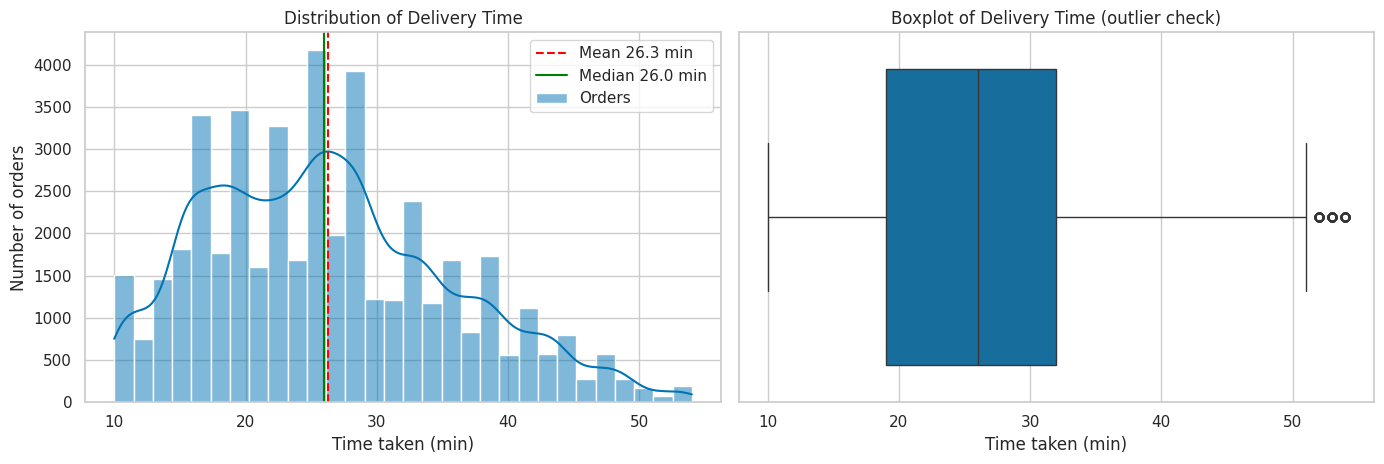

,count,mean,std,min,25%,50%,75%,max
Time_taken,45593.0000,26.2946,9.3838,10.0000,19.0000,26.0000,32.0000,54.0000


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(df['Time_taken'], bins=30, kde=True, ax=axes[0], label='Orders')
axes[0].axvline(df['Time_taken'].mean(), color='red', linestyle='--', label=f"Mean {df['Time_taken'].mean():.1f} min")
axes[0].axvline(df['Time_taken'].median(), color='green', label=f"Median {df['Time_taken'].median():.1f} min")
axes[0].set_title('Distribution of Delivery Time')
axes[0].set_xlabel('Time taken (min)')
axes[0].set_ylabel('Number of orders')
axes[0].legend()
sns.boxplot(x=df['Time_taken'], ax=axes[1])
axes[1].set_title('Boxplot of Delivery Time (outlier check)')
axes[1].set_xlabel('Time taken (min)')
plt.tight_layout()
plt.show()
display(df['Time_taken'].describe().to_frame().T)

#### Observation 2.1: Target
- Delivery time runs from **10 to 54 minutes**, with **mean 26.3** and **median 26.0 minutes** (std 9.4). The distribution is only slightly right-skewed, so no log-transform is needed.
- The boxplot shows **no extreme outliers**: every value is a plausible urban delivery time, so none are removed.
- The target takes **whole-minute values only** (45 distinct values). This explains the striped patterns in the residual plots later.

#### 2.2 Feature distributions

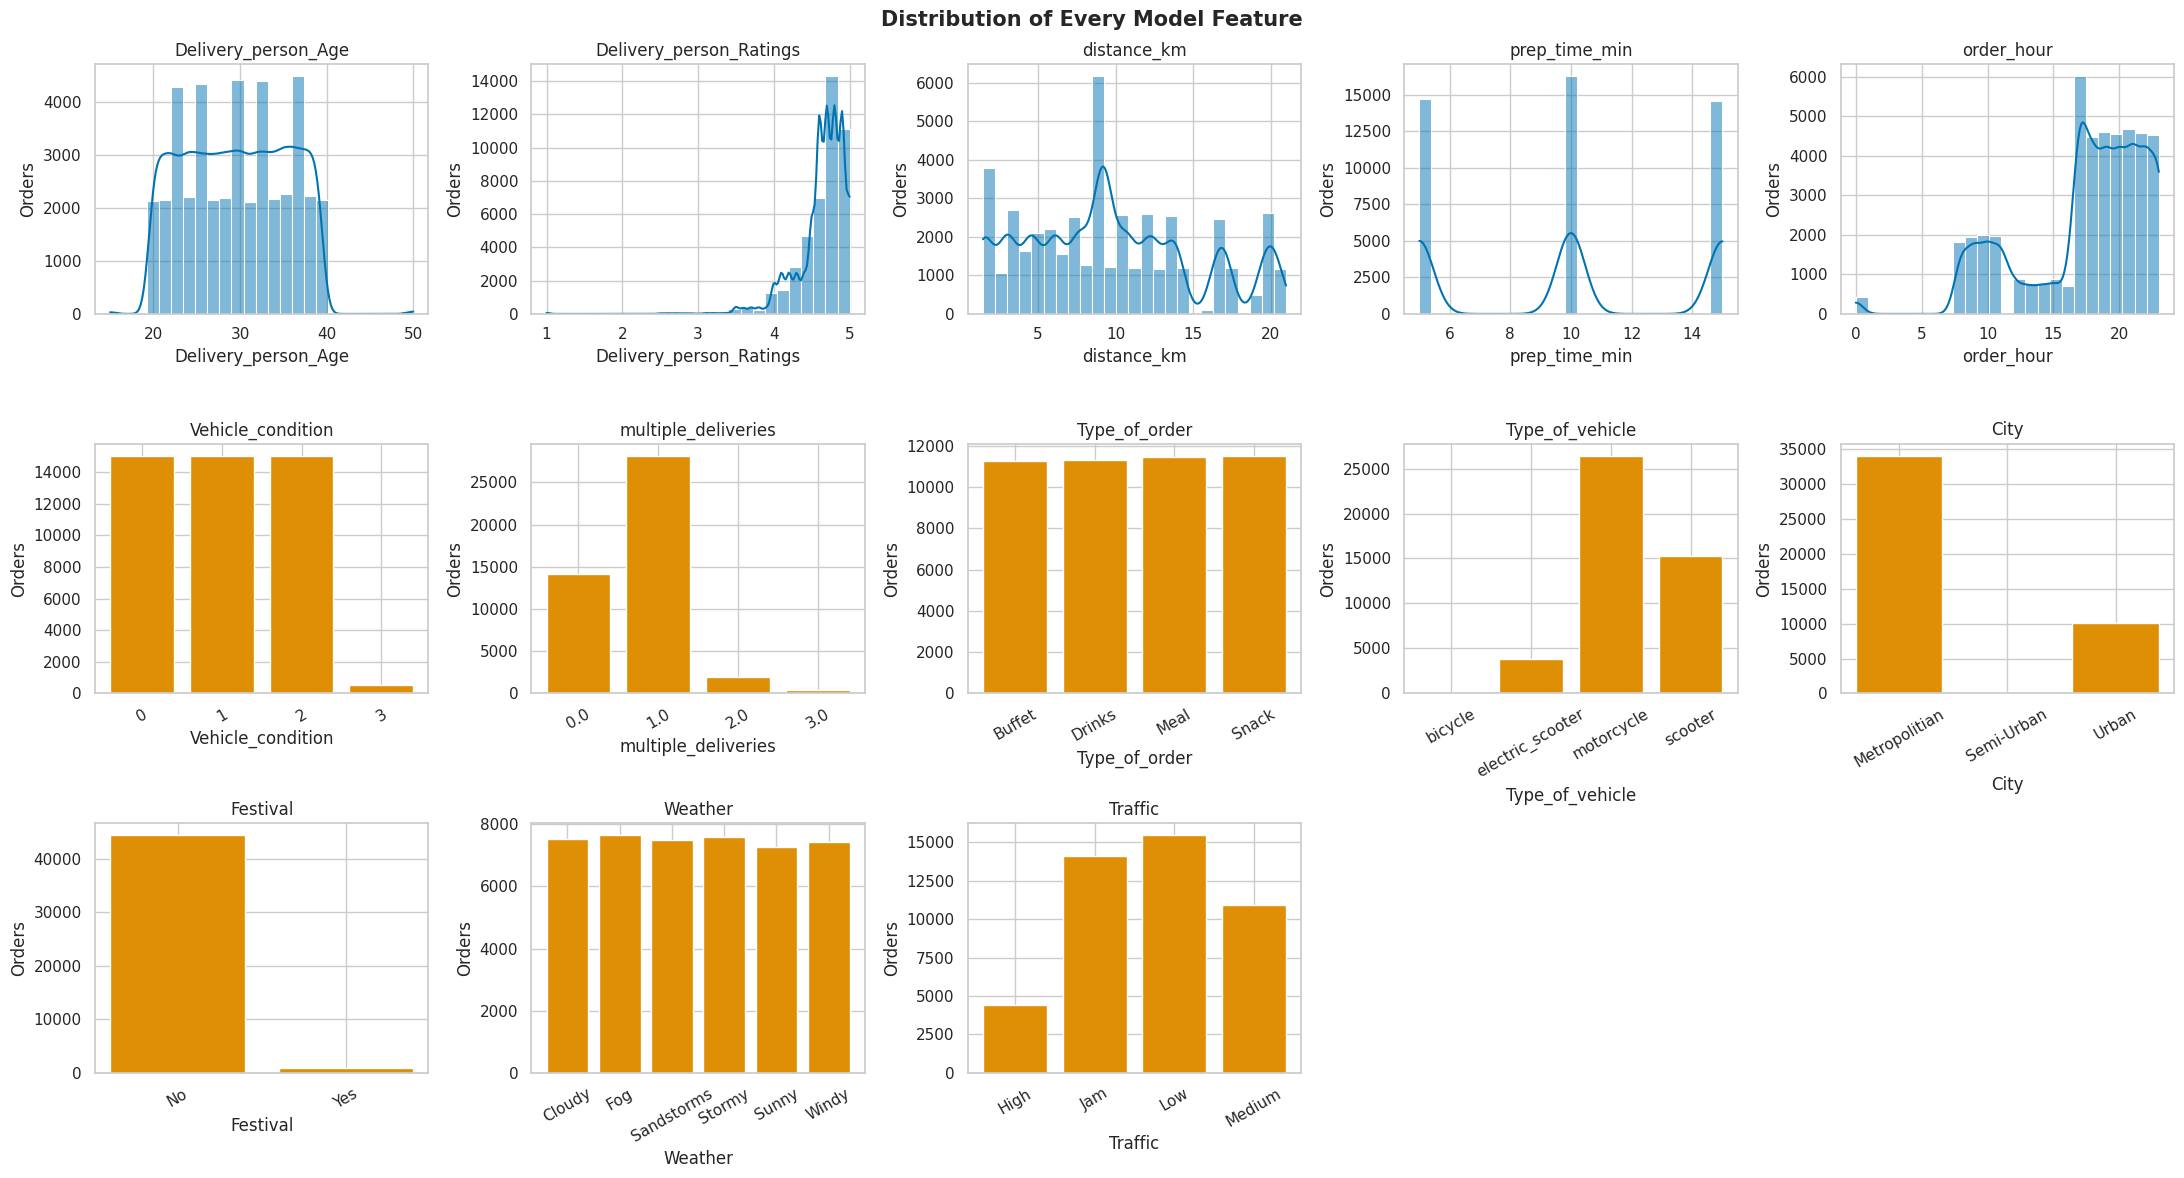

In [5]:
num_feats = ['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'prep_time_min', 'order_hour']
cat_feats = ['Vehicle_condition', 'multiple_deliveries', 'Type_of_order', 'Type_of_vehicle', 'City',
             'Festival', 'Weather', 'Traffic']
fig, axes = plt.subplots(3, 5, figsize=(22, 12))
axes = axes.ravel()
for ax, col in zip(axes, num_feats):
    sns.histplot(df[col].dropna(), bins=25, kde=True, ax=ax)
    ax.set_title(f'{col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Orders')
for ax, col in zip(axes[len(num_feats):], cat_feats):
    counts = df[col].value_counts(dropna=True).sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=sns.color_palette('colorblind')[1])
    ax.set_title(f'{col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Orders')
    ax.tick_params(axis='x', rotation=30)
for ax in axes[len(num_feats) + len(cat_feats):]:
    ax.set_visible(False)
fig.suptitle('Distribution of Every Model Feature', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### Observation 2.2: Feature distributions
- **Rider age** is spread evenly between 20 and 39. **Ratings** are strongly left-skewed: most riders score 4.5–5.0, with a thin tail down to 1.0.
- **Distance** ranges from 1.5 to 21 km (mean 9.7 km). **`prep_time_min` only takes 5, 10 or 15 minutes**: the pickup time is rounded, so this feature carries little detail.
- **`order_hour`** is bimodal, with a morning block (8–11) and a much larger evening block (17–23). The evening is the main operating window.
- **Order types and weather types are almost perfectly balanced** (about 25% and 16% each). **Festival days are rare** (about 2%), as are **3 multiple deliveries** and **Semi-Urban** cities (164 orders), so any conclusions about these groups rest on few rows.

#### 2.3 Correlation heatmap

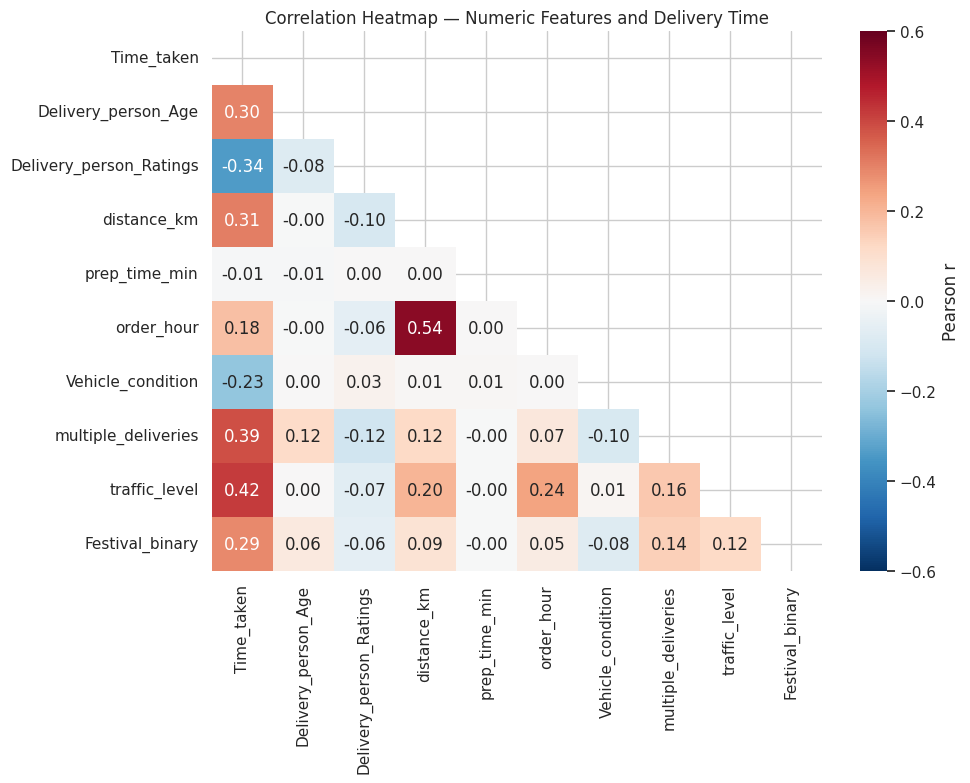

,r with Time_taken
traffic_level,0.4185
multiple_deliveries,0.3871
Delivery_person_Ratings,-0.3411
distance_km,0.3074
Delivery_person_Age,0.2995
Festival_binary,0.2900
Vehicle_condition,-0.2344
order_hour,0.1806
prep_time_min,-0.0083


In [6]:
corr_cols = ['Time_taken', 'Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'prep_time_min',
             'order_hour', 'Vehicle_condition', 'multiple_deliveries', 'traffic_level', 'Festival_binary']
corr = df[corr_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation Heatmap — Numeric Features and Delivery Time')
plt.tight_layout()
plt.show()
display(corr['Time_taken'].drop('Time_taken').sort_values(key=abs, ascending=False).to_frame('r with Time_taken'))

#### Observation 2.3: Correlations with delivery time
- The strongest linear drivers are **traffic level (r = +0.42)**, **multiple deliveries (+0.39)**, **rider rating (−0.34)**, **distance (+0.31)**, **rider age (+0.30)** and **festival (+0.29)**.
- **`prep_time_min` has essentially no linear link (r ≈ −0.01)**. Because it only takes three rounded values, it cannot explain much.
- The strongest link between two predictors is **distance vs. order hour (|r| ≈ 0.54)**: evening orders travel further. Every other pair is weaker, so **multicollinearity is only moderate** for the linear models.
- No single feature explains most of the variance. This suggests the models will need to **combine** features, which favours non-linear methods.

#### 2.4 Feature–target scatter plots

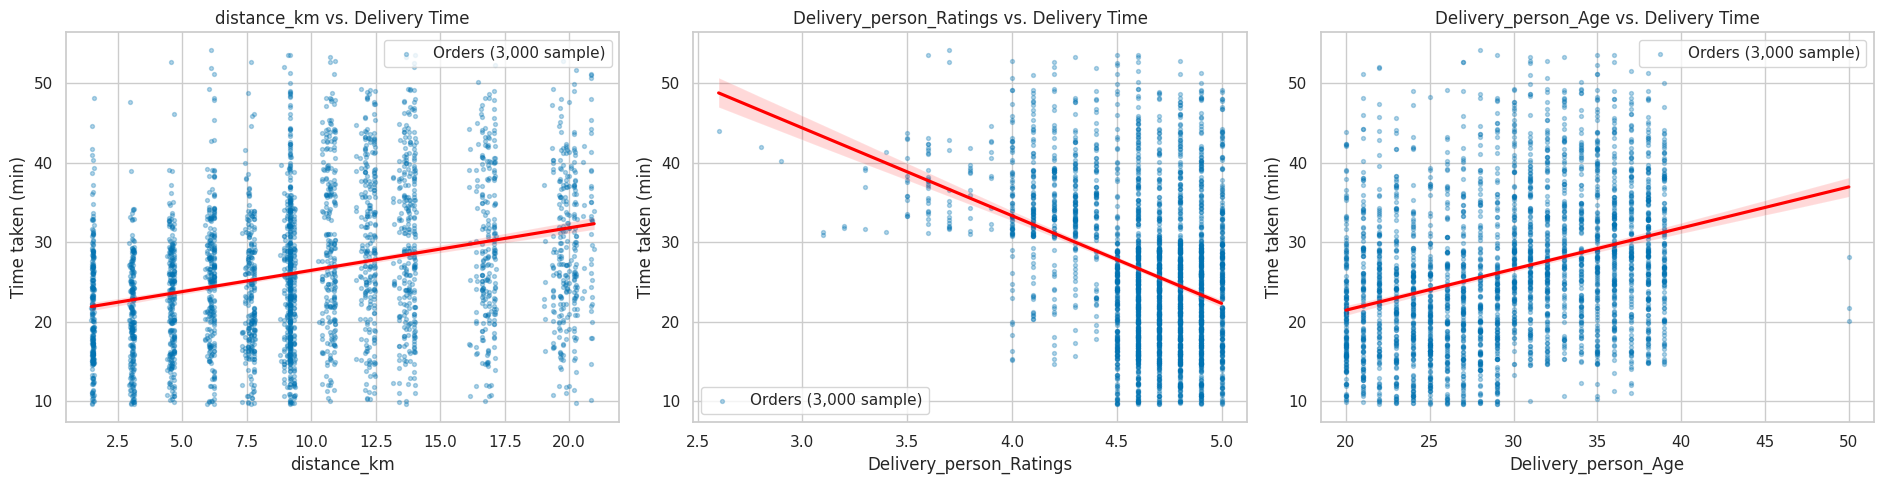

In [7]:
sample = df.sample(3000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, col in zip(axes, ['distance_km', 'Delivery_person_Ratings', 'Delivery_person_Age']):
    jitter = np.random.RandomState(0).uniform(-0.4, 0.4, len(sample))   # target is in whole minutes
    ax.scatter(sample[col], sample['Time_taken'] + jitter, s=8, alpha=0.3, label='Orders (3,000 sample)')
    sns.regplot(data=sample, x=col, y='Time_taken', scatter=False, ax=ax, color='red',
                line_kws={'label': 'Linear trend'})
    ax.set_title(f'{col} vs. Delivery Time')
    ax.set_xlabel(col)
    ax.set_ylabel('Time taken (min)')
    ax.legend()
plt.tight_layout()
plt.show()

#### Observation 2.4: Feature–target scatter plots
- **Distance** has a clear upward trend. At any given distance, though, times vary by 20+ minutes, so distance alone cannot give an accurate prediction.
- **Ratings** show a strong downward trend. Riders rated below 4.0 (1,367 orders) have a **median time of 36 minutes**, and 62% of their orders take 35+ minutes. This is a threshold effect a tree can capture directly.
- **Age** trends upward, but in a step: riders up to 30 average about 23–24 min, while riders aged 31–40 average about 29.5 min.

#### 2.5 Categorical drivers: weather, traffic, festival, workload

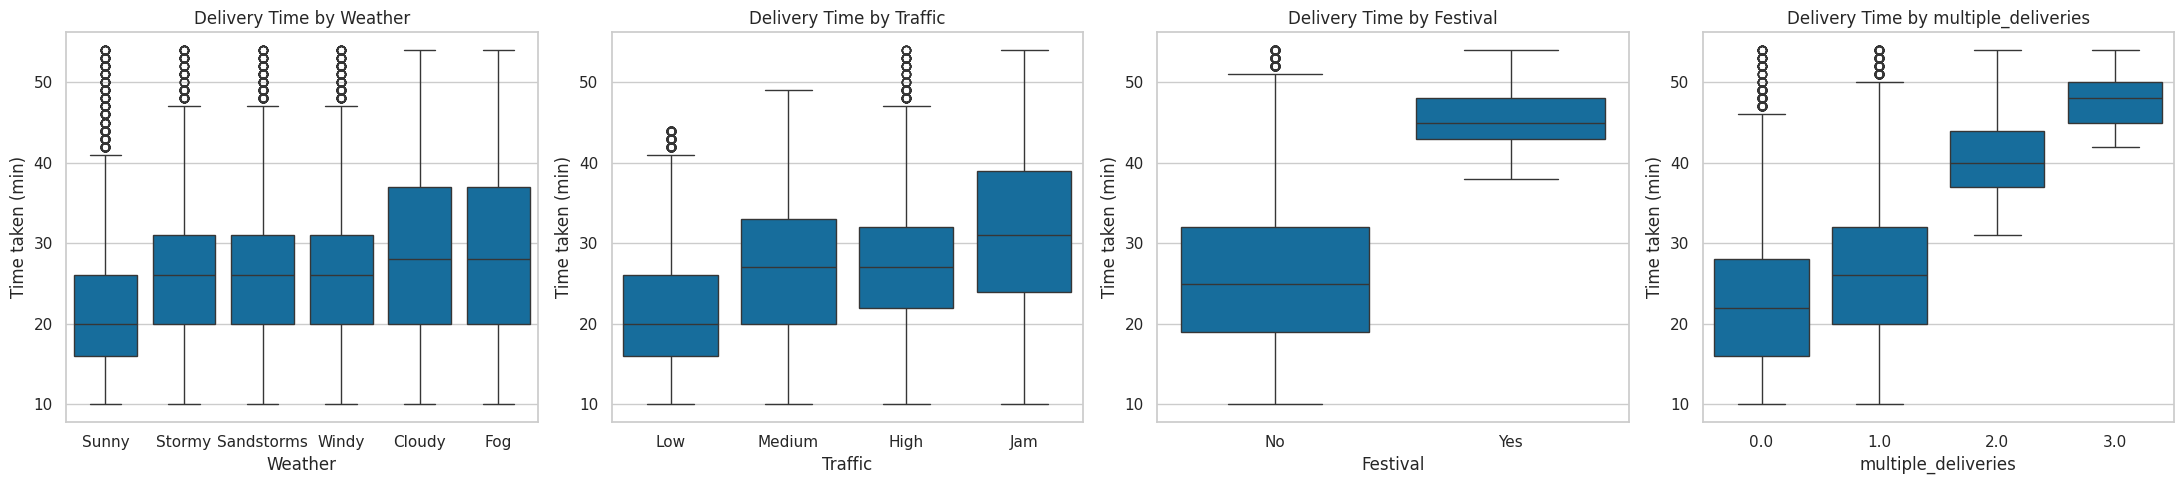

Median minutes
Weather              Cloudy             28.0000
                     Fog                28.0000
                     Sandstorms         26.0000
                     Stormy             26.0000
                     Sunny              20.0000
                     Windy              26.0000
Traffic              High               27.0000
                     Jam                31.0000
                     Low                20.0000
                     Medium             27.0000
Festival             No                 25.0000
                     Yes                45.0000
multiple_deliveries 0.0000              22.0000
                    1.0000              26.0000
                    2.0000              40.0000
                    3.0000              48.0000

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
panels = [('Weather', ['Sunny', 'Stormy', 'Sandstorms', 'Windy', 'Cloudy', 'Fog']),
          ('Traffic', ['Low', 'Medium', 'High', 'Jam']),
          ('Festival', ['No', 'Yes']),
          ('multiple_deliveries', [0.0, 1.0, 2.0, 3.0])]
for ax, (col, order) in zip(axes, panels):
    sns.boxplot(data=df, x=col, y='Time_taken', order=order, ax=ax)
    ax.set_title(f'Delivery Time by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Time taken (min)')
plt.tight_layout()
plt.show()
display(pd.concat({c: df.groupby(c)['Time_taken'].median() for c, _ in panels}).to_frame('Median minutes'))

#### Observation 2.5: Categorical drivers
- **Weather:** Sunny has a median of **20 min**, against 26–28 min for every other condition. Fog and Cloudy are the slowest.
- **Traffic:** the median rises from **20 min (Low)** to **27 (Medium/High)** and **31 (Jam)**.
- **Festival:** the median jumps from **25 to 45 minutes**. This is the largest single effect in the data.
- **Workload:** the median rises from 22 min (0 extra deliveries) to 26, **40 and 48 min** (1, 2 and 3 extra deliveries).
- These step-like effects are exactly what tree-based models capture easily and straight-line models do not.

---
### 3. Preprocessing & feature engineering  [Rubric B1 / B2 / B3]
#### 3.1 Cleaning (B1) — done by `clean_and_engineer()`
| Issue | Treatment | Why |
|---|---|---|
| Text tokens `'NaN'`, `'conditions NaN'` | Converted to real `NaN` | So imputers can see them |
| Numbers stored as text | Cast to numeric | Age, rating, multiple deliveries |
| Ratings > 5 (53 rows) | Capped at 5.0 | Impossible on a 1–5 scale |
| (0, 0) or near-zero coordinates (3,640 rows) | Distance replaced by median | Would create 1,000+ km trips |
| Missing numerics / categoricals | Median / most-frequent imputation, **fitted on train only** | Median is robust to skew |
| Duplicates | Checked: 0 duplicated rows or IDs | Nothing to remove |

#### 3.2 Engineered features (B3)
| Feature | Justification |
|---|---|
| `distance_km` (Haversine) | Raw lat/long are meaningless to a model; the distance between them is the physical driver of travel time |
| `prep_time_min` | Separates kitchen delay (order → pickup) from road time |
| `order_hour`, `is_rush_hour` | Captures lunch (12–14) and dinner (19–21) peaks |
| `is_weekend` | Weekend demand patterns differ |
| `Festival_binary` | Festival days bring demand surges |

#### 3.3 Encoding, scaling & splitting (B2)
80:20 split (`random_state=42`), **stratified on the `Is_Delayed` flag** so that the regression, classification and clustering notebooks share the exact same train and test orders. Scaler and one-hot encoder are fitted on the training set only.

In [9]:
X = df[NUMERICAL_COLS + CATEGORICAL_COLS]
y = df['Time_taken']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=df['Is_Delayed'])

preprocessor = build_preprocessor()
X_train_p = preprocessor.fit_transform(X_train)   # fit on TRAIN only
X_test_p = preprocessor.transform(X_test)
feature_names = get_feature_names(preprocessor)
sub_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_train_p), 8000, replace=False)  # for SVR

print(f'Train: {X_train_p.shape} | Test: {X_test_p.shape} | features: {len(feature_names)}')
print(f'Mean target  train: {y_train.mean():.2f} min | test: {y_test.mean():.2f} min')

Train: (36474, 23) | Test: (9119, 23) | features: 23
Mean target  train: 26.27 min | test: 26.39 min


---
### 4. Training all 10 regression algorithms  [Rubric C1]
A single helper fits each model and records R², RMSE and MAE on the same test set.

In [10]:
reg_results, reg_preds, reg_models = {}, {}, {}


def evaluate_regressor(name, model, X_tr=None, y_tr=None, X_te=None):
    """Fit a regressor, predict the shared test set and store R2 / RMSE / MAE."""
    X_tr = X_train_p if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_te = X_test_p if X_te is None else X_te
    start = time.time()
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    reg_results[name] = {'R2': r2_score(y_test, preds),
                         'RMSE': np.sqrt(mean_squared_error(y_test, preds)),
                         'MAE': mean_absolute_error(y_test, preds),
                         'Train time (s)': time.time() - start}
    reg_preds[name], reg_models[name] = preds, model
    r = reg_results[name]
    print(f"[{name:<30}] R2 {r['R2']:.4f} | RMSE {r['RMSE']:.3f} | MAE {r['MAE']:.3f}")
    return model

#### 4.1 Models 1–4: Linear, Ridge, Lasso, ElasticNet

In [11]:
lin = evaluate_regressor('Linear Regression', LinearRegression())
ridge = evaluate_regressor('Ridge Regression', Ridge(alpha=10.0))
lasso = evaluate_regressor('Lasso Regression', Lasso(alpha=0.05, random_state=RANDOM_STATE))
enet = evaluate_regressor('ElasticNet Regression', ElasticNet(alpha=0.05, l1_ratio=0.5, random_state=RANDOM_STATE))

coef_df = pd.DataFrame({'Linear': lin.coef_, 'Ridge': ridge.coef_, 'Lasso': lasso.coef_, 'ElasticNet': enet.coef_},
                       index=feature_names)
coef_df = coef_df.reindex(coef_df['Linear'].abs().sort_values(ascending=False).index)
display(coef_df.style.format('{:+.3f}').background_gradient(cmap='RdBu_r', vmin=-8, vmax=8))
print(f'Lasso set {int((lasso.coef_ == 0).sum())} of {len(feature_names)} coefficients exactly to zero:',
      [f for f, c in zip(feature_names, lasso.coef_) if c == 0])

[Linear Regression             ] R2 0.5918 | RMSE 5.997 | MAE 4.756
[Ridge Regression              ] R2 0.5921 | RMSE 5.995 | MAE 4.756
[Lasso Regression              ] R2 0.5844 | RMSE 6.051 | MAE 4.787
[ElasticNet Regression         ] R2 0.5786 | RMSE 6.093 | MAE 4.828


,Linear,Ridge,Lasso,ElasticNet
City_Semi-Urban,+10.494,+9.740,+0.000,+0.490
Road_traffic_density_Low,-6.695,-6.642,-5.450,-4.102
Weatherconditions_Sunny,-6.138,-6.105,-4.933,-4.026
Type_of_vehicle_scooter,-4.321,-2.945,-0.492,-0.565
Type_of_vehicle_motorcycle,-3.779,-2.396,+0.000,+0.000
Type_of_vehicle_electric_scooter,-3.307,-1.931,+0.000,+0.000
Weatherconditions_Sandstorms,-2.752,-2.725,-1.549,-1.098
Weatherconditions_Stormy,-2.726,-2.700,-1.538,-1.086
Road_traffic_density_Medium,-2.660,-2.614,-1.361,-0.323
Weatherconditions_Windy,-2.570,-2.544,-1.356,-0.925


Lasso set 5 of 23 coefficients exactly to zero: ['prep_time_min', 'is_weekend', 'City_Semi-Urban', 'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle']


#### Observation 4.1: Linear, Ridge, Lasso and ElasticNet
- All four linear models explain about **58–59% of the variance (R² ≈ 0.58–0.59, RMSE ≈ 6.0 min)**. This sets the baseline.
- **Largest linear effects:** Low traffic (−6.7 min), Sunny weather (−6.1 min), rider rating (−2.2 min per std), rider age (+2.2), distance (+1.9), multiple deliveries (+1.7) and festival (+1.4).
- `City_Semi-Urban` has a coefficient of +10.5 in plain Linear Regression because its 164 orders average **49.7 min**. **Lasso sets it to exactly 0**: with so few rows, the L1 penalty judges the coefficient not worth its cost.
- **Lasso zeroed 5 of 23 features**: `prep_time_min`, `is_weekend`, `City_Semi-Urban`, and the electric-scooter and motorcycle dummies. This is L1 feature selection. The first two also showed almost no correlation in EDA.
- **Ridge** mainly shrinks the correlated vehicle dummies (scooter −4.3 → −2.9) and leaves the strong predictors unchanged. It improves R² only slightly (0.5918 → 0.5921), which is expected with only moderate multicollinearity.

#### 4.2 Model 5: Polynomial Regression — comparing degrees
Polynomial terms are built from the 10 scaled numeric features (the one-hot columns are added unchanged), then fitted with Linear Regression. Degree 1 is plain linear regression and is included for reference.

In [12]:
n_num = len(NUMERICAL_COLS)
poly_rows = []
for degree in [1, 2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    Xtr_poly = np.hstack([poly.fit_transform(X_train_p[:, :n_num]), X_train_p[:, n_num:]])
    Xte_poly = np.hstack([poly.transform(X_test_p[:, :n_num]), X_test_p[:, n_num:]])
    m = LinearRegression().fit(Xtr_poly, y_train)
    poly_rows.append({'Degree': degree, 'Features': Xtr_poly.shape[1],
                      'Train R2': r2_score(y_train, m.predict(Xtr_poly)),
                      'Test R2': r2_score(y_test, m.predict(Xte_poly))})
    if degree == 2:
        X_train_poly2, X_test_poly2 = Xtr_poly, Xte_poly
display(pd.DataFrame(poly_rows).set_index('Degree'))

# Degree 2 is kept as the official Polynomial Regression model
evaluate_regressor('Polynomial Regression (deg 2)', LinearRegression(),
                   X_tr=X_train_poly2, X_te=X_test_poly2);

,Features,Train R2,Test R2
Degree,,,
1,23,0.5780,0.5918
2,78,0.6115,0.6252
3,298,0.6517,0.6618


[Polynomial Regression (deg 2) ] R2 0.6252 | RMSE 5.747 | MAE 4.581


#### Observation 4.2: Polynomial degree comparison
- Test R² rises from **0.592 (degree 1)** to **0.625 (degree 2)** and **0.662 (degree 3)**, while the number of features grows from 23 to 78 to 298.
- Train and test R² stay close at every degree, so **no overfitting yet**. The gains show there are real interactions (for example rating × distance).
- Even degree 3 is far below the tree models (Section 5). Polynomials add smooth curves, but the data has **step-like threshold effects** (festival, multiple deliveries ≥ 2, rating < 4) that polynomials fit poorly. Degree 2 is kept as the official model, as in Review 1, because it keeps the feature space manageable.

#### 4.3 Model 6: Decision Tree — tuning `max_depth`

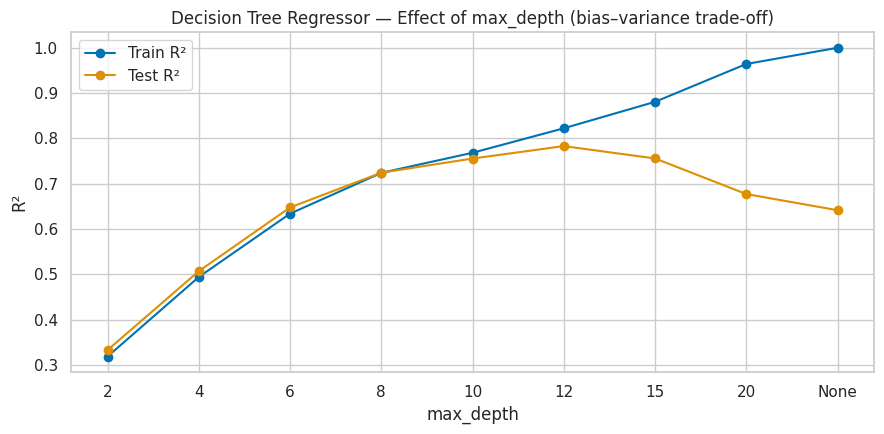

Best max_depth on test: 12
[Decision Tree Regressor       ] R2 0.7828 | RMSE 4.374 | MAE 3.413


In [13]:
depth_rows = []
for d in [2, 4, 6, 8, 10, 12, 15, 20, None]:
    m = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE).fit(X_train_p, y_train)
    depth_rows.append({'max_depth': str(d), 'Train R2': r2_score(y_train, m.predict(X_train_p)),
                       'Test R2': r2_score(y_test, m.predict(X_test_p))})
depth_df = pd.DataFrame(depth_rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(depth_df['max_depth'], depth_df['Train R2'], marker='o', label='Train R²')
ax.plot(depth_df['max_depth'], depth_df['Test R2'], marker='o', label='Test R²')
ax.set_title('Decision Tree Regressor — Effect of max_depth (bias–variance trade-off)')
ax.set_xlabel('max_depth')
ax.set_ylabel('R²')
ax.legend()
plt.tight_layout()
plt.show()

best_depth = int(depth_df.loc[depth_df['Test R2'].idxmax(), 'max_depth'])
print(f'Best max_depth on test: {best_depth}')
evaluate_regressor('Decision Tree Regressor', DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE));

#### Observation 4.3: Decision Tree depth
- Train R² keeps rising with depth, but **test R² peaks at max_depth = 12 (0.783)** and then falls. This is the classic bias–variance trade-off: shallow trees underfit, deep trees memorise individual orders.
- The tuned tree (depth 12) is much better than the depth-8 tree from Review 1 (0.724) and already beats every linear model by about 0.19 R².

#### 4.4 Models 7–8: Random Forest and Gradient Boosting
Baseline settings here; both are tuned with GridSearchCV in Section 6.

In [14]:
evaluate_regressor('Random Forest Regressor', RandomForestRegressor(
    n_estimators=100, max_depth=14, random_state=RANDOM_STATE, n_jobs=-1))
evaluate_regressor('Gradient Boosting Regressor', GradientBoostingRegressor(
    n_estimators=120, learning_rate=0.1, max_depth=5, random_state=RANDOM_STATE));

[Random Forest Regressor       ] R2 0.8102 | RMSE 4.089 | MAE 3.222


[Gradient Boosting Regressor   ] R2 0.7985 | RMSE 4.214 | MAE 3.346


#### 4.5 Model 9: Support Vector Regressor — tuning `C` and `kernel`
SVR is sensitive to feature scale (the RBF kernel uses Euclidean distance), so it uses the standardised matrix. Training cost grows about quadratically with the number of rows, so the kernel/C search uses 5,000 rows and the final model uses the fixed 8,000-row subset.

In [15]:
svr_grid = GridSearchCV(SVR(epsilon=0.2), {'kernel': ['linear', 'rbf', 'poly'], 'C': [1, 5, 10]},
                        cv=3, scoring='r2', n_jobs=-1)
svr_grid.fit(X_train_p[sub_idx[:5000]], y_train.iloc[sub_idx[:5000]])
svr_cv = (pd.DataFrame(svr_grid.cv_results_)[['param_kernel', 'param_C', 'mean_test_score']]
          .pivot(index='param_C', columns='param_kernel', values='mean_test_score'))
display(svr_cv.style.format('{:.4f}').background_gradient(cmap='Greens')
        .set_caption('SVR 3-fold CV R² by kernel (columns) and C (rows)'))
print('Best SVR setting:', svr_grid.best_params_)
evaluate_regressor('Support Vector Regressor (SVR)', SVR(epsilon=0.2, **svr_grid.best_params_),
                   X_tr=X_train_p[sub_idx], y_tr=y_train.iloc[sub_idx]);

param_kernel,linear,poly,rbf
param_C,,,
1,0.5757,0.5631,0.6253
5,0.5764,0.5623,0.6752
10,0.5760,0.4121,0.6836


Best SVR setting: {'C': 10, 'kernel': 'rbf'}


[Support Vector Regressor (SVR)] R2 0.7204 | RMSE 4.964 | MAE 3.887


#### Observation 4.4: SVR kernel and C
- **The RBF kernel wins at every C.** Linear SVR stays at about 0.576 CV R², the same as linear regression. The polynomial kernel is unstable and collapses to 0.41 at C = 10.
- A larger C (less regularisation) helps the RBF kernel: 0.625 → 0.675 → 0.684. The final SVR (RBF, C = 10, trained on 8,000 rows) reaches **test R² 0.720**.
- SVR needs scaled features and cannot use all 36k rows at a reasonable cost. Both limits keep it behind the tree ensembles.

#### 4.6 Model 10: K-Nearest Neighbours — tuning `k` and the impact of scaling
To show why scaling matters, KNN is also run on **unscaled** features (imputed only).

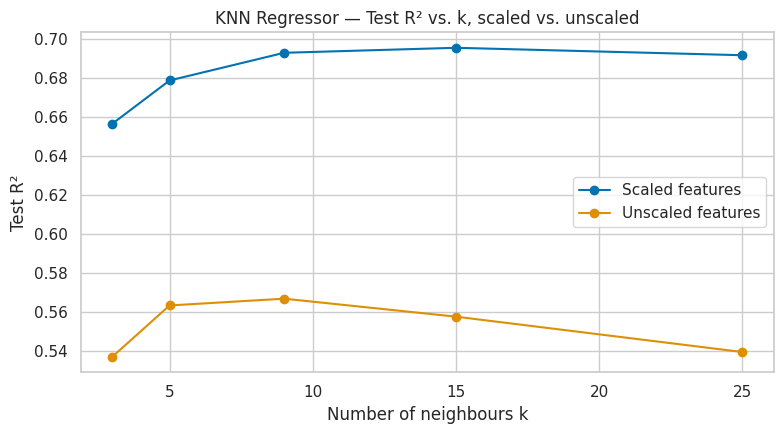

Features,Scaled,Unscaled
k,,
3,0.6564,0.5370
5,0.6786,0.5633
9,0.6928,0.5668
15,0.6953,0.5576
25,0.6915,0.5394


[K-Nearest Neighbors Regressor ] R2 0.6953 | RMSE 5.181 | MAE 4.047


In [16]:
unscaled_prep = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUMERICAL_COLS),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]),
     CATEGORICAL_COLS)])
X_train_raw = unscaled_prep.fit_transform(X_train)
X_test_raw = unscaled_prep.transform(X_test)

knn_rows = []
for k in [3, 5, 9, 15, 25]:
    for label, (Xtr, Xte) in {'Scaled': (X_train_p, X_test_p), 'Unscaled': (X_train_raw, X_test_raw)}.items():
        m = KNeighborsRegressor(n_neighbors=k, weights='distance', n_jobs=-1).fit(Xtr, y_train)
        knn_rows.append({'k': k, 'Features': label, 'Test R2': r2_score(y_test, m.predict(Xte))})
knn_df = pd.DataFrame(knn_rows).pivot(index='k', columns='Features', values='Test R2')

fig, ax = plt.subplots(figsize=(8, 4.5))
for col in knn_df.columns:
    ax.plot(knn_df.index, knn_df[col], marker='o', label=f'{col} features')
ax.set_title('KNN Regressor — Test R² vs. k, scaled vs. unscaled')
ax.set_xlabel('Number of neighbours k')
ax.set_ylabel('Test R²')
ax.legend()
plt.tight_layout()
plt.show()
display(knn_df)

best_k = int(knn_df['Scaled'].idxmax())
evaluate_regressor('K-Nearest Neighbors Regressor', KNeighborsRegressor(n_neighbors=best_k, weights='distance', n_jobs=-1));

#### Observation 4.5: KNN and the impact of scaling
- **Scaling raises KNN's R² by about 0.13** (best 0.695 scaled vs 0.567 unscaled). Without scaling, `order_hour` (0–23) and `distance_km` (1–21) dominate the Euclidean distance, and the one-hot flags (0/1) and rating (1–5) are almost ignored.
- Test R² improves up to **k = 15 (0.695)** and then declines. Small k is noisy (high variance); large k averages over neighbours that are too different (high bias).

---
### 5. Comparative evaluation — all 10 models  [Rubric C2]

,Rank,R2,RMSE,MAE,Train time (s)
Algorithm,,,,,
Random Forest Regressor,1,0.8102,4.089,3.222,4.5
Gradient Boosting Regressor,2,0.7985,4.214,3.346,6.8
Decision Tree Regressor,3,0.7828,4.374,3.413,0.1
Support Vector Regressor (SVR),4,0.7204,4.964,3.887,6.3
K-Nearest Neighbors Regressor,5,0.6953,5.181,4.047,0.7
Polynomial Regression (deg 2),6,0.6252,5.747,4.581,0.1
Ridge Regression,7,0.5921,5.995,4.756,0.0
Linear Regression,8,0.5918,5.997,4.756,0.0
Lasso Regression,9,0.5844,6.051,4.787,0.0


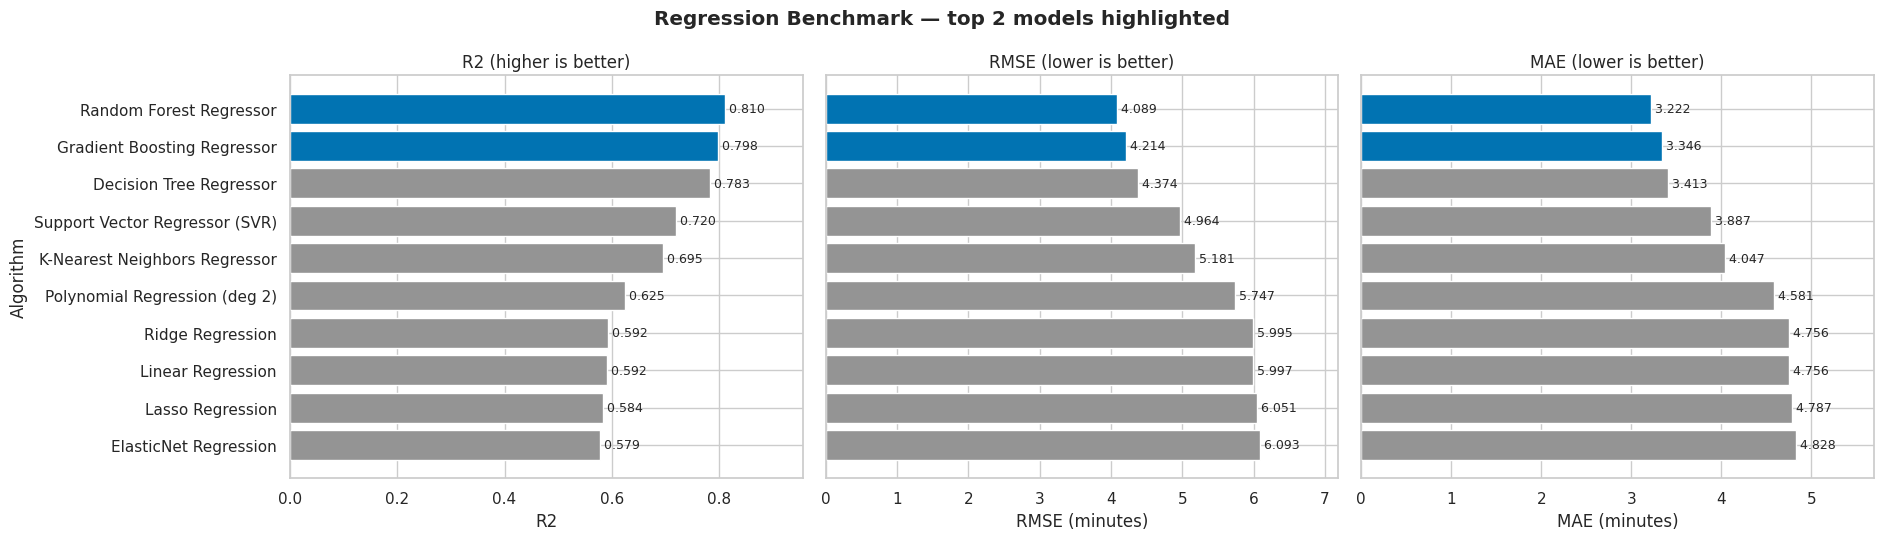

In [17]:
reg_summary = pd.DataFrame.from_dict(reg_results, orient='index').sort_values('R2', ascending=False)
reg_summary.index.name = 'Algorithm'
reg_summary.insert(0, 'Rank', range(1, len(reg_summary) + 1))
display(reg_summary.style.format({'R2': '{:.4f}', 'RMSE': '{:.3f}', 'MAE': '{:.3f}', 'Train time (s)': '{:.1f}'})
        .background_gradient(cmap='Blues', subset=['R2'])
        .background_gradient(cmap='Blues_r', subset=['RMSE', 'MAE'])
        .set_caption('All 10 regression algorithms — same test split (n = 9,119), ranked by R²'))

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharey=True)
order = reg_summary.index[::-1]
for ax, metric in zip(axes, ['R2', 'RMSE', 'MAE']):
    vals = reg_summary.loc[order, metric]
    ax.barh(order, vals, color=[sns.color_palette('colorblind')[0] if n in reg_summary.index[:2]
                                else sns.color_palette('colorblind')[7] for n in order], label=metric)
    for yy, v in enumerate(vals):
        ax.text(v, yy, f' {v:.3f}', va='center', fontsize=9)
    ax.set_title(f"{metric} ({'higher' if metric == 'R2' else 'lower'} is better)")
    ax.set_xlabel(metric if metric == 'R2' else f'{metric} (minutes)')
    ax.set_xlim(0, vals.max() * 1.18)
axes[0].set_ylabel('Algorithm')
fig.suptitle('Regression Benchmark — top 2 models highlighted', fontweight='bold')
plt.tight_layout()
plt.show()

#### 5.1 Five-fold cross-validated R² for the two best models

In [18]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name in reg_summary.index[:2]:
    cv_r2 = cross_val_score(reg_models[name], X_train_p, y_train, cv=kf, scoring='r2', n_jobs=-1)
    cv_rows.append({'Algorithm': name, 'CV R2 mean': cv_r2.mean(), 'CV R2 std': cv_r2.std(),
                    'Test R2': reg_results[name]['R2'], 'R2 per fold': np.round(cv_r2, 4).tolist()})
display(pd.DataFrame(cv_rows).set_index('Algorithm'))

,CV R2 mean,CV R2 std,Test R2,R2 per fold
Algorithm,,,,
Random Forest Regressor,0.8046,0.0029,0.8102,"[0.8014, 0.8012, 0.8053, 0.8068, 0.8083]"
Gradient Boosting Regressor,0.7930,0.0026,0.7985,"[0.7911, 0.7937, 0.7915, 0.791, 0.7978]"


#### Observation 5: Ranking and cross-validation
- **Random Forest is the best untuned model (R² 0.810, RMSE 4.09 min, MAE 3.22 min)**, followed by Gradient Boosting (0.799) and the tuned Decision Tree (0.783).
- There is a clear gap between the **tree family (0.78–0.81)** and the **distance/kernel models (SVR 0.72, KNN 0.70)**, with the **linear family (0.58–0.63)** last.
- **5-fold CV confirms the top 2:** Random Forest 0.805 ± 0.003, Gradient Boosting 0.793 ± 0.003. Fold-to-fold spread is under 0.01, and the CV means are within 0.006 of the test scores, so there is no sign of overfitting to the test split.

---
### 6. Hyperparameter tuning  [Rubric C3]
GridSearchCV is applied to three model families: **Ridge** (`alpha`), **Random Forest** (`n_estimators`, `max_depth`, `min_samples_leaf`) and **Gradient Boosting** (`learning_rate`, `n_estimators`, `max_depth`). The tree searches use 3-fold CV on a fixed 10,000-row training slice to save time. The best setting is then refitted on the full training set and scored on the test set.

In [19]:
tune_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_train_p), 10000, replace=False)
searches = {
    'Ridge Regression': (Ridge(), {'alpha': [0.01, 0.1, 1, 10, 50, 100, 200]}, None),
    'Random Forest Regressor': (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                                {'n_estimators': [100, 300], 'max_depth': [14, None], 'min_samples_leaf': [1, 3]}, tune_idx),
    'Gradient Boosting Regressor': (GradientBoostingRegressor(random_state=RANDOM_STATE),
                                    {'learning_rate': [0.05, 0.1, 0.2], 'n_estimators': [200, 400], 'max_depth': [5, 7]}, tune_idx),
}
tuned, tune_rows = {}, []
for name, (est, grid, idx) in searches.items():
    start = time.time()
    Xs, ys = (X_train_p, y_train) if idx is None else (X_train_p[idx], y_train.iloc[idx])
    gs = GridSearchCV(est, grid, cv=3 if idx is not None else 5, scoring='r2', n_jobs=-1).fit(Xs, ys)
    best = gs.best_estimator_.fit(X_train_p, y_train)
    p = best.predict(X_test_p)
    tuned[name] = best
    tune_rows.append({'Algorithm': name, 'Best parameters': gs.best_params_,
                      'Baseline R2': reg_results[name]['R2'], 'Tuned R2': r2_score(y_test, p),
                      'Baseline RMSE': reg_results[name]['RMSE'], 'Tuned RMSE': np.sqrt(mean_squared_error(y_test, p)),
                      'Tuned MAE': mean_absolute_error(y_test, p), 'Search time (s)': time.time() - start})
    print(f'{name:<28} {gs.best_params_}  ({time.time() - start:.0f}s)')
tune_df = pd.DataFrame(tune_rows).set_index('Algorithm')
tune_df['R2 change'] = tune_df['Tuned R2'] - tune_df['Baseline R2']
tune_df['RMSE change (min)'] = tune_df['Tuned RMSE'] - tune_df['Baseline RMSE']
display(tune_df)

Ridge Regression             {'alpha': 0.01}  (0s)


Random Forest Regressor      {'max_depth': 14, 'min_samples_leaf': 1, 'n_estimators': 300}  (64s)


Gradient Boosting Regressor  {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 200}  (87s)


,Best parameters,Baseline R2,Tuned R2,Baseline RMSE,Tuned RMSE,Tuned MAE,Search time (s),R2 change,RMSE change (min)
Algorithm,,,,,,,,,
Ridge Regression,{'alpha': 0.01},0.5921,0.5918,5.9953,5.9972,4.7564,0.3908,-0.0003,0.0019
Random Forest Regressor,"{'max_depth': 14, 'min_samples_leaf': 1, 'n_es...",0.8102,0.8108,4.0892,4.0824,3.2157,64.1721,0.0006,-0.0068
Gradient Boosting Regressor,"{'learning_rate': 0.05, 'max_depth': 7, 'n_est...",0.7985,0.8134,4.2136,4.0548,3.2133,86.7258,0.0149,-0.1587


#### Observation 6: Hyperparameter tuning
- **Gradient Boosting gained the most: R² 0.799 → 0.813 (+0.015), RMSE 4.21 → 4.05 min.** The search picked deeper trees (`max_depth=7`) with a smaller `learning_rate=0.05` and 200 trees, allowing richer interactions without overfitting.
- **Random Forest barely moved (0.810 → 0.811).** Going from 100 to 300 trees only reduces variance a little, and depth 14 was already well chosen in Review 1. Random Forest is known to work well with default settings.
- **Ridge picked alpha = 0.01** (essentially no regularisation) and its test R² did not change (−0.0003). With 36k rows, only 23 features and moderate multicollinearity, there is little variance for regularisation to remove.
- **After tuning, Gradient Boosting overtakes Random Forest** and becomes the best regression model.

---
### 7. Diagnostics for the best model  [Rubric C4]

Best model after tuning: Gradient Boosting Regressor | R2 0.8134 | RMSE 4.055 | MAE 3.213
Share of test orders predicted within ±5 min: 80.0%


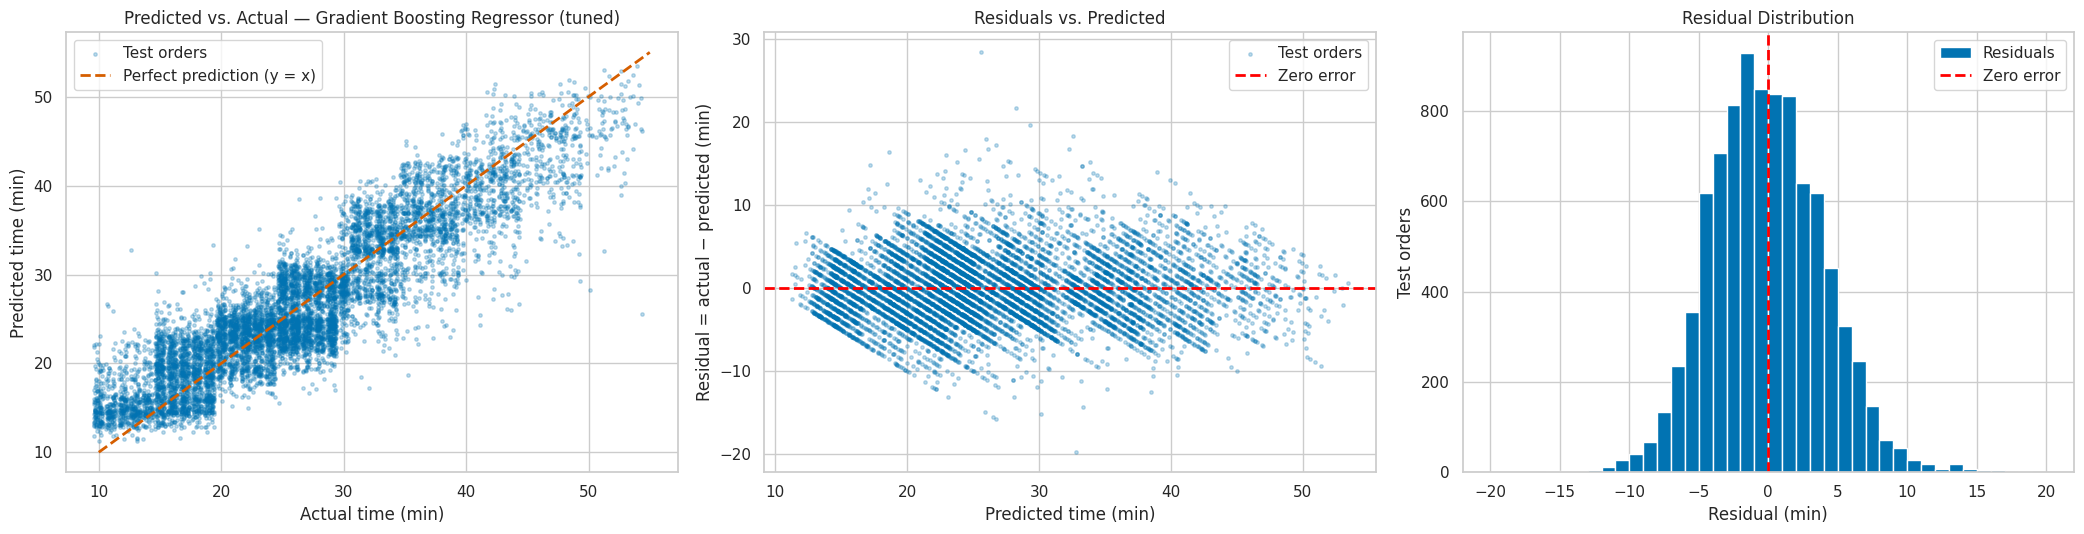

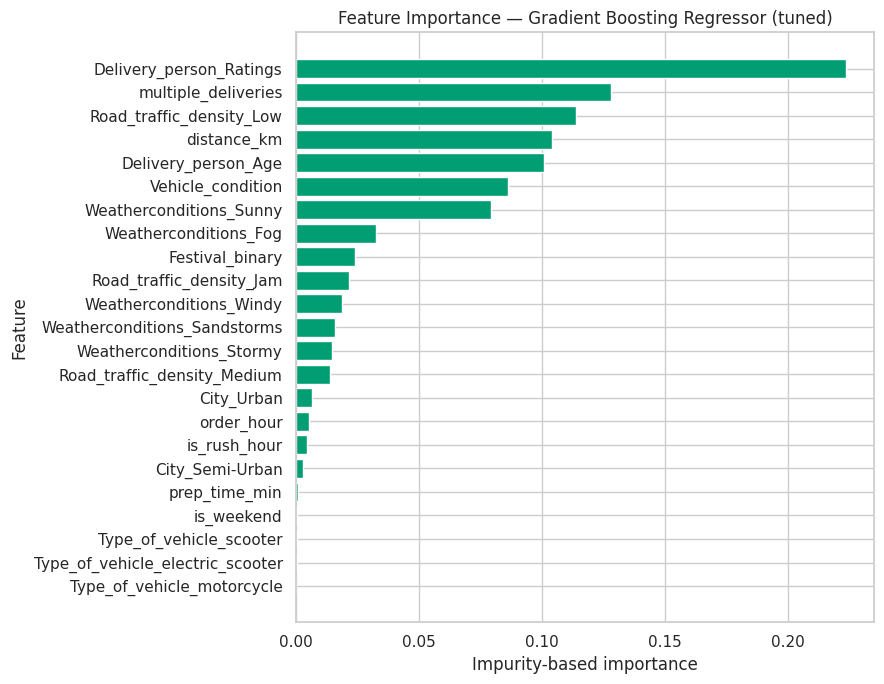

Delivery_person_Ratings    0.2240
multiple_deliveries        0.1280
Road_traffic_density_Low   0.1140
distance_km                0.1040
Delivery_person_Age        0.1010
Vehicle_condition          0.0860
Weatherconditions_Sunny    0.0790
Weatherconditions_Fog      0.0330


In [20]:
best_name = tune_df['Tuned R2'].idxmax()
best_model = tuned[best_name]
best_pred = best_model.predict(X_test_p)
resid = y_test.values - best_pred
print(f'Best model after tuning: {best_name} | R2 {r2_score(y_test, best_pred):.4f} | '
      f'RMSE {np.sqrt(mean_squared_error(y_test, best_pred)):.3f} | MAE {mean_absolute_error(y_test, best_pred):.3f}')
print(f'Share of test orders predicted within ±5 min: {(np.abs(resid) <= 5).mean() * 100:.1f}%')

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
jit = np.random.RandomState(0).uniform(-0.4, 0.4, len(y_test))
axes[0].scatter(y_test + jit, best_pred, s=6, alpha=0.25, label='Test orders')
axes[0].plot([10, 55], [10, 55], 'r--', lw=2, label='Perfect prediction (y = x)')
axes[0].set_title(f'Predicted vs. Actual — {best_name} (tuned)')
axes[0].set_xlabel('Actual time (min)')
axes[0].set_ylabel('Predicted time (min)')
axes[0].legend()

axes[1].scatter(best_pred, resid, s=6, alpha=0.25, label='Test orders')
axes[1].axhline(0, color='red', linestyle='--', lw=2, label='Zero error')
axes[1].set_title('Residuals vs. Predicted')
axes[1].set_xlabel('Predicted time (min)')
axes[1].set_ylabel('Residual = actual − predicted (min)')
axes[1].legend()

axes[2].hist(resid, bins=np.arange(-20, 20.5, 1), label='Residuals')
axes[2].axvline(0, color='red', linestyle='--', lw=2, label='Zero error')
axes[2].set_title('Residual Distribution')
axes[2].set_xlabel('Residual (min)')
axes[2].set_ylabel('Test orders')
axes[2].legend()
plt.tight_layout()
plt.show()

imp = pd.Series(best_model.feature_importances_, index=feature_names).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(imp.index, imp.values, color=sns.color_palette('colorblind')[2])
ax.set_title(f'Feature Importance — {best_name} (tuned)')
ax.set_xlabel('Impurity-based importance')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()
print(imp.sort_values(ascending=False).head(8).round(3).to_string())

#### Observation 7: Diagnostics of the tuned Gradient Boosting model
- **Predicted vs. actual:** points follow the y = x line closely from 15 to 45 minutes. The model **over-predicts the fastest orders** (10–14 min, predicted about 14–16) and **under-predicts some of the slowest** (45+ min). Extreme values are pulled towards the mean, which is normal for squared-error models.
- **Residuals:** centred on 0 and roughly bell-shaped, with no funnel shape (constant variance). **80% of test orders are predicted within ±5 minutes.** The diagonal stripes come from the whole-minute target, not from model bias.
- **Feature importance:** rider rating (0.22), multiple deliveries (0.13), Low traffic (0.11), distance (0.10), rider age (0.10), vehicle condition (0.09) and Sunny weather (0.08). This matches the EDA findings.

---
## 8. Observations: which regression model performs best, and why

### Best model: tuned Gradient Boosting Regressor
`GradientBoostingRegressor(learning_rate=0.05, max_depth=7, n_estimators=200)`: **R² 0.813, RMSE 4.05 min, MAE 3.21 min** on the 9,119-order test set. The closest alternative is the tuned Random Forest (R² 0.811, RMSE 4.08, MAE 3.22). Before tuning, Random Forest led (0.810 vs 0.799).

**Why the boosted tree ensemble wins**
1. **The effects are thresholds and interactions.** Festival days (+20 min median), 2 or more multiple deliveries (+14–22 min), ratings below about 4 and Jam traffic all behave like switches. Trees model a switch with a single split, while linear models (R² ≈ 0.59) and polynomials (≤ 0.66) try to bend a smooth curve through it.
2. **Boosting fixes errors step by step.** Each new tree fits the residuals of the current ensemble, so difficult combinations (for example a low-rated rider in Jam traffic on a festival day) get extra attention. With a small learning rate and depth-7 trees, it captures these high-order interactions while staying stable. This is where the +0.015 R² from tuning comes from.
3. **No scaling or distance assumptions.** KNN (0.70) and SVR (0.72) depend on Euclidean distance in a mixed space of continuous and one-hot features, and SVR can only be trained on a subset. Trees split each feature on its own scale.
4. **It generalises.** The CV R² of the Gradient Boosting family (0.793 ± 0.003) sits close to its test score, and residuals show no systematic pattern.

**Trade-off:** Random Forest is almost as accurate (−0.003 R²), trains in parallel, and needs less tuning. If simplicity and robustness matter more than the last 0.1 minute of RMSE, it is a strong fallback. Remaining error (RMSE ≈ 4 min) comes mostly from factors not in the data, such as the real road route, weather intensity and restaurant queue length.

---
## 9. Save the final regression model (used by the Streamlit GUI)
The tuned Gradient Boosting Regressor and its **train-fitted** preprocessor are saved together, so the GUI applies exactly the same imputation, scaling and one-hot encoding as this notebook. The same file format is used by `src/train_models.py` and `app/app.py`.

In [ ]:
import os, joblib, sklearn

MODELS_DIR = '../models' if os.path.basename(os.getcwd()) == 'notebooks' else 'models'
os.makedirs(MODELS_DIR, exist_ok=True)
joblib.dump({'preprocessor': preprocessor, 'model': best_model, 'features': NUMERICAL_COLS + CATEGORICAL_COLS,
             'feature_names': feature_names, 'name': f'{best_name} (tuned)', 'sklearn_version': sklearn.__version__,
             'n_train': len(X_train), 'n_test': len(X_test),
             'metrics': {'R2': r2_score(y_test, best_pred),
                         'RMSE': float(np.sqrt(mean_squared_error(y_test, best_pred))),
                         'MAE': mean_absolute_error(y_test, best_pred),
                         'within_5_min': float((np.abs(resid) <= 5).mean()),
                         'resid_std': float(resid.std())}},
            os.path.join(MODELS_DIR, 'best_regressor.pkl'), compress=3)
print(f'Saved {MODELS_DIR}/best_regressor.pkl  ->  {best_name}, test R2 = {r2_score(y_test, best_pred):.4f}')